In [ ]:
!git clone https://github.com/vsitzmann/siren.git
%cd siren
!ls

Cloning into 'siren'...
remote: Enumerating objects: 193, done.
remote: Total 193 (delta 0), reused 0 (delta 0), pack-reused 193 (from 1)
Receiving objects: 100% (193/193), 2.17 MiB | 42.82 MiB/s, done.
Resolving deltas: 100% (70/70), done.
/content/siren
data		   experiment_scripts	make_figures.py  sdf_meshing.py
dataio.py	   explore_siren.ipynb	meta_modules.py  torchmeta
diff_operators.py  LICENSE		modules.py	 training.py
environment.yml    loss_functions.py	README.md	 utils.py


**Clone the official repository.** Clones the official SIREN code from GitHub, changes into the repository folder, and lists its contents to confirm the clone succeeded.

In [ ]:
!pip install -q cmapy scikit-video opencv-python moviepy imageio-ffmpeg h5py networkx pywavelets scikit-image scikit-learn configargparse

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


**Install dependencies.** Installs the packages the official scripts import that are not preinstalled in Colab (e.g. `cmapy`, `scikit-video`, `configargparse`). Colab already provides PyTorch, NumPy, SciPy and TensorBoard, so the conda `environment.yml` is not needed.

In [ ]:
!python experiment_scripts/train_img.py --model_type=sine --experiment_name=siren_image_fit

I0000 00:00:1794794599.470380   12013 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794794599.501611   12013 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794794600.693036   12013 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794794600.693297   12013 cudart_stub.cc:31] Could not find cuda drivers on your machine, 

**Image fitting: SIREN.** Trains the official image-fitting experiment (`train_img.py`, paper Fig. 1) with sine activations (`--model_type=sine`) on the cameraman image, using the script's default settings.

In [ ]:
!python experiment_scripts/train_img.py --model_type=relu --experiment_name=cmp_relu
!python experiment_scripts/train_img.py --model_type=tanh --experiment_name=cmp_tanh

I0000 00:00:1794794885.591518   13521 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794794885.623144   13521 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794794886.827037   13521 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794794886.827297   13521 cudart_stub.cc:31] Could not find cuda drivers on your machine, 

**Image fitting: ReLU and Tanh baselines.** Runs the same image-fitting experiment with ReLU and Tanh activations, so they can be compared with SIREN as in Fig. 1.

In [ ]:
!python experiment_scripts/train_img.py --model_type=nerf --experiment_name=cmp_nerf

I0000 00:00:1794795353.141343   16120 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794795353.173336   16120 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794795354.397391   16120 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794795354.397667   16120 cudart_stub.cc:31] Could not find cuda drivers on your machine, 

**Image fitting: ReLU with positional encoding.** Runs the ReLU P.E. baseline (`--model_type=nerf`: ReLU MLP with NeRF-style positional encoding).

In [ ]:
!python experiment_scripts/train_img.py --model_type=rbf --experiment_name=cmp_rbf

I0000 00:00:1794795573.184268   17372 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794795573.215977   17372 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794795574.420994   17372 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794795574.421258   17372 cudart_stub.cc:31] Could not find cuda drivers on your machine, 

**Image fitting: RBF-ReLU.** Runs the RBF-ReLU baseline (`--model_type=rbf`: an RBF input layer followed by ReLU layers). Together with the previous runs this covers all five columns of Fig. 1.

In [ ]:
from tensorboard.backend.event_processing import event_accumulator
import glob, os

runs = {
    "SIREN": "siren_image_fit",
    "ReLU":  "cmp_relu",
    "Tanh":  "cmp_tanh",
    "NeRF (ReLU P.E.)": "cmp_nerf",
    "RBF-ReLU": "cmp_rbf",
}

for label, exp_name in runs.items():
    summ_dir = f"./logs/{exp_name}/summaries"
    if not os.path.isdir(summ_dir):
        print(f"[{label}] Directory not found: {summ_dir}")
        continue
    ea = event_accumulator.EventAccumulator(summ_dir, size_guidance={'scalars': 0, 'images': 0})
    ea.Reload()
    tags = ea.Tags()
    print(f"=== {label} ({exp_name}) ===")
    print("  scalars:", tags.get('scalars'))
    print("  images :", tags.get('images'))
    print()

=== SIREN (siren_image_fit) ===
  scalars: ['img_loss', 'total_train_loss', 'train_img_psnr', 'train_img_ssim']
  images : ['train_gt_vs_pred', 'train_pred_img', 'train_pred_grad', 'train_pred_lapl', 'train_gt_img', 'train_gt_grad', 'train_gt_lapl']

=== ReLU (cmp_relu) ===
  scalars: ['img_loss', 'total_train_loss', 'train_img_psnr', 'train_img_ssim']
  images : ['train_gt_vs_pred', 'train_pred_img', 'train_pred_grad', 'train_pred_lapl', 'train_gt_img', 'train_gt_grad', 'train_gt_lapl']

=== Tanh (cmp_tanh) ===
  scalars: ['img_loss', 'total_train_loss', 'train_img_psnr', 'train_img_ssim']
  images : ['train_gt_vs_pred', 'train_pred_img', 'train_pred_grad', 'train_pred_lapl', 'train_gt_img', 'train_gt_grad', 'train_gt_lapl']

=== NeRF (ReLU P.E.) (cmp_nerf) ===
  scalars: ['img_loss', 'total_train_loss', 'train_img_psnr', 'train_img_ssim']
  images : ['train_gt_vs_pred', 'train_pred_img', 'train_pred_grad', 'train_pred_lapl', 'train_gt_img', 'train_gt_grad', 'train_gt_lapl']

=== RBF-

**Inspect the TensorBoard logs.** Opens the TensorBoard summaries of the five image-fitting runs and prints which scalar and image tags each run logged. The tag names are needed to extract the PSNR curves and the reconstruction / gradient / Laplacian images in the next step.

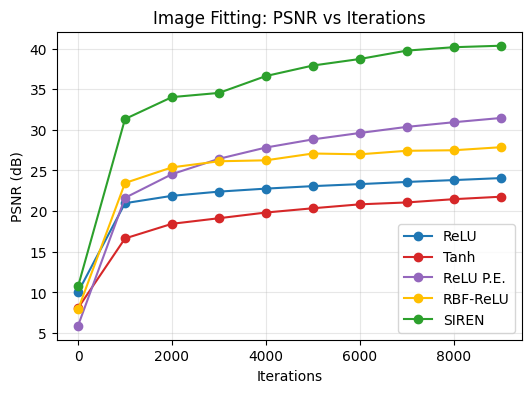

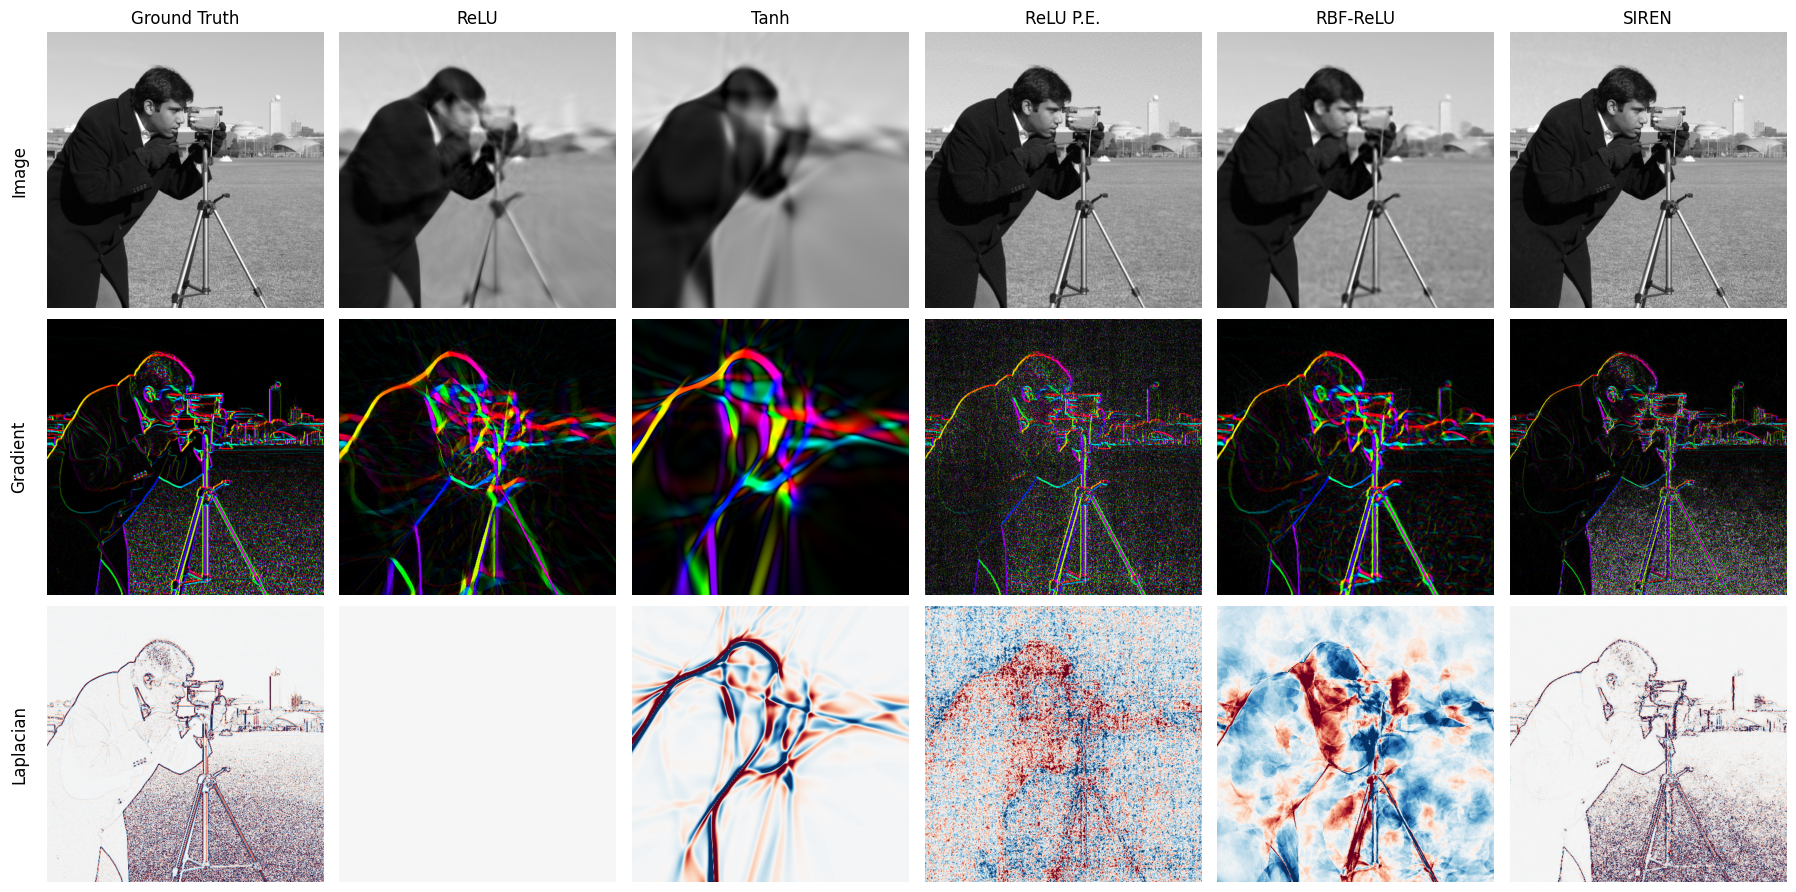

In [ ]:
import os, io
import matplotlib.pyplot as plt
from PIL import Image
from tensorboard.backend.event_processing import event_accumulator

runs = {
    "ReLU":       "cmp_relu",
    "Tanh":       "cmp_tanh",
    "ReLU P.E.":  "cmp_nerf",
    "RBF-ReLU":   "cmp_rbf",
    "SIREN":      "siren_image_fit",
}

def load_ea(exp_name):
    ea = event_accumulator.EventAccumulator(
        f"./logs/{exp_name}/summaries",
        size_guidance={'scalars': 0, 'images': 0}
    )
    ea.Reload()
    return ea

eas = {label: load_ea(exp) for label, exp in runs.items()}

def get_last_image(ea, tag):
    enc = ea.Images(tag)[-1].encoded_image_string
    return Image.open(io.BytesIO(enc))

# ---------------- 1) PSNR curve comparison ----------------
# ---------------- 1) PSNR curve comparison ----------------
color_map = {
    "ReLU":      "#1f77b4",  # blue
    "Tanh":      "#d62728",  # red
    "ReLU P.E.": "#9467bd",  # purple
    "RBF-ReLU":  "#ffbf00",  # yellow/gold
    "SIREN":     "#2ca02c",  # green
}

plt.figure(figsize=(6, 4))
for label, ea in eas.items():
    events = ea.Scalars('train_img_psnr')
    steps = [e.step for e in events]
    vals  = [e.value for e in events]
    plt.plot(steps, vals, marker='o', label=label, color=color_map[label])
plt.xlabel("Iterations")
plt.ylabel("PSNR (dB)")
plt.title("Image Fitting: PSNR vs Iterations")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("psnr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------- 2) Five-column (+GT) grid: reconstruction / gradient / Laplacian ----------------
col_order = ["ReLU", "Tanh", "ReLU P.E.", "RBF-ReLU", "SIREN"]

gt_img  = get_last_image(eas["SIREN"], "train_gt_img")
gt_grad = get_last_image(eas["SIREN"], "train_gt_grad")
gt_lapl = get_last_image(eas["SIREN"], "train_gt_lapl")

imgs  = [gt_img]  + [get_last_image(eas[l], "train_pred_img")  for l in col_order]
grads = [gt_grad] + [get_last_image(eas[l], "train_pred_grad") for l in col_order]
lapls = [gt_lapl] + [get_last_image(eas[l], "train_pred_lapl") for l in col_order]

col_labels = ["Ground Truth"] + col_order
rows = [imgs, grads, lapls]
row_labels = ["Image", "Gradient", "Laplacian"]

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for r in range(3):
    for c in range(6):
        axes[r][c].imshow(rows[r][c])
        axes[r][c].axis("off")
        if r == 0:
            axes[r][c].set_title(col_labels[c], fontsize=12)
        if c == 0:
            axes[r][c].text(-0.1, 0.5, row_labels[r], transform=axes[r][c].transAxes,
                             rotation=90, va='center', ha='center', fontsize=12)
plt.tight_layout()
plt.savefig("fig1_reproduction.png", dpi=200, bbox_inches="tight")
plt.show()

**Reproduce Fig. 1.** Loads the five runs' TensorBoard logs, then (1) plots the PSNR-vs-iteration curves of all models with the paper's color scheme and saves `psnr_curve.png`, and (2) takes the last logged ground-truth and predicted image, gradient and Laplacian of each model and arranges them in a 3 × 6 grid (Ground Truth, ReLU, Tanh, ReLU P.E., RBF-ReLU, SIREN), saved as `fig1_reproduction.png`.

In [ ]:
# ================= Video experiment setup: download the cat video + fix the environment =================
!pip install -q -U gdown scikit-video
import gdown, os, glob

FOLDER_URL = "https://drive.google.com/drive/folders/1_iq__37-hw7FJOEUK1tX7mdp8SKB368K"


files = gdown.download_folder(FOLDER_URL, skip_download=True, quiet=True)
videos = [f for f in files if f.path.lower().endswith((".mp4", ".npy"))]
print("Video files in the shared folder:")
for f in videos:
    print(f"  {f.path}   id={f.id}")


npy = next((f for f in videos if os.path.basename(f.path) == "video_512.npy"), None)
mp4 = next((f for f in videos if "cat" in os.path.basename(f.path).lower()
            and f.path.lower().endswith(".mp4")), None)

if npy:
    out = "/content/siren/data/video_512.npy"
    if not (os.path.exists(out) and os.path.getsize(out) > 0):
        gdown.download(id=npy.id, output=out, quiet=False)
    print(f"✅ Using the official npy: {out}; train_video.py needs no change")
elif mp4:
    out = "/content/cat_video.mp4"
    if not (os.path.exists(out) and os.path.getsize(out) > 0):
        gdown.download(id=mp4.id, output=out, quiet=False)
    !sed -i "s|'./data/video_512.npy'|'/content/cat_video.mp4'|" /content/siren/experiment_scripts/train_video.py
    print(f"✅ Using the mp4: {out}; pointed the cat branch of train_video.py to it")
else:
    raise FileNotFoundError("Cat video not found in the shared folder; see the file list printed above")

!grep -n "video_512\|cat_video" /content/siren/experiment_scripts/train_video.py


import skvideo
SKV = os.path.dirname(skvideo.__file__)
!sed -i -E 's/\bnp\.int\b/int/g; s/\bnp\.float\b/float/g; s/\bnp\.bool\b/bool/g' \
  $(grep -rlE '\bnp\.(int|float|bool)\b' {SKV})
leftover = !grep -rnE '\bnp\.(int|float|bool)\b' {SKV}
print("scikit-video fix complete" if not leftover else f"Remaining occurrences: {leftover[:3]}")

**Video experiment setup.** Lists the video files in the authors' shared Google Drive folder and downloads the cat video. If the official `video_512.npy` is available it is placed where `train_video.py` expects it; otherwise the cat `.mp4` is downloaded and the script's cat-dataset path is pointed to it. It then patches the installed `scikit-video` package, replacing the `np.int` / `np.float` / `np.bool` aliases removed in newer NumPy, so that video loading works.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!python experiment_scripts/train_video.py \
    --model_type=sine --dataset=cat --experiment_name=video_cat_sine \
    --logging_root=/content/drive/MyDrive/siren_reproduction/logs

!python experiment_scripts/train_video.py \
    --model_type=relu --dataset=cat --experiment_name=video_cat_relu \
    --logging_root=/content/drive/MyDrive/siren_reproduction/logs

**Video fitting: SIREN and ReLU.** Mounts Google Drive and trains the official video-fitting experiment (`train_video.py`, paper Fig. 2) on the cat video, first with SIREN and then with ReLU, using the default settings. Logs and checkpoints are written to Drive so they survive a disconnect.

GT 在上半部分 (diff_top=0.00, diff_bot=7.31)


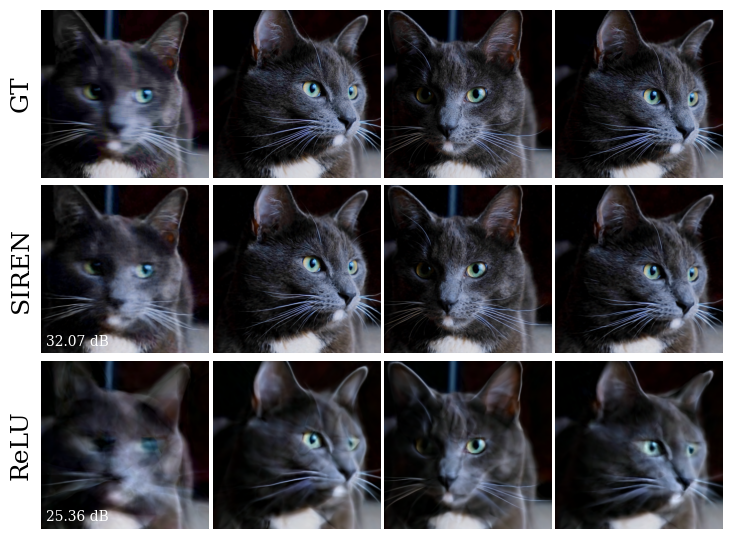

In [ ]:
import io
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def get_raw(ea):
    enc = ea.Images('train_output_vs_gt')[-1].encoded_image_string
    return np.array(Image.open(io.BytesIO(enc)).convert("RGB"))

raw_s = get_raw(eas["SIREN"])
raw_r = get_raw(eas["ReLU"])

TILE, PAD = 512, 2
n_frames = (raw_s.shape[1] - PAD) // (TILE + PAD)   # = 4

def split_frames(raw):
    tops, bots = [], []
    for i in range(n_frames):
        x0 = PAD + i * (TILE + PAD)
        y0 = PAD
        tops.append(raw[y0:y0+TILE,        x0:x0+TILE])
        bots.append(raw[y0+TILE:y0+2*TILE, x0:x0+TILE])
    return tops, bots

top_s, bot_s = split_frames(raw_s)
top_r, bot_r = split_frames(raw_r)

# The half that is identical in the SIREN and ReLU images is the GT
diff_top = np.mean([np.abs(a.astype(float) - b.astype(float)).mean() for a, b in zip(top_s, top_r)])
diff_bot = np.mean([np.abs(a.astype(float) - b.astype(float)).mean() for a, b in zip(bot_s, bot_r)])
if diff_top < diff_bot:
    gt_frames, siren_frames, relu_frames = top_s, bot_s, bot_r
else:
    gt_frames, siren_frames, relu_frames = bot_s, top_s, top_r
print(f"GT is in the {'top' if diff_top < diff_bot else 'bottom'} half (diff_top={diff_top:.2f}, diff_bot={diff_bot:.2f})")

# ---------------- Paper Fig.2 style: 3 rows × N frames ----------------
rows = [
    ("GT",    gt_frames,    None),
    ("SIREN", siren_frames, final_psnr["SIREN"]),
    ("ReLU",  relu_frames,  final_psnr["ReLU"]),
]

fig, axes = plt.subplots(3, n_frames, figsize=(2.2 * n_frames, 6.8))
for r, (label, frames, psnr) in enumerate(rows):
    for c in range(n_frames):
        ax = axes[r][c]
        ax.imshow(frames[c])
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        if c == 0:
            ax.set_ylabel(label, fontsize=18, fontfamily="serif", labelpad=6)
            if psnr is not None:
                ax.text(0.03, 0.03, f"{psnr:.2f} dB", transform=ax.transAxes,
                        fontsize=10, fontfamily="serif", color="white",
                        va="bottom", ha="left")

plt.subplots_adjust(wspace=0.02, hspace=0.02)
plt.savefig("fig2_reproduction.png", dpi=200, bbox_inches="tight")
plt.savefig("fig2_reproduction.pdf", bbox_inches="tight")
plt.show()

**Reproduce Fig. 2.** Takes the last `train_output_vs_gt` image logged by each video run, cuts it into individual frames (four 512 × 512 tiles, each with the ground truth and the prediction stacked), and identifies the ground-truth half as the one that is identical in the SIREN and ReLU logs. It then lays out a GT / SIREN / ReLU grid in the style of Fig. 2, with each model's final PSNR on its first frame, and saves `fig2_reproduction.png` / `.pdf`. This cell uses `eas` and `final_psnr` from the cell that loads the video runs' TensorBoard logs.

In [ ]:
!wget -q https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/grouping/BSR/BSR_bsds500.tgz -O /content/bsr.tgz
!tar -xzf /content/bsr.tgz -C /content/
!mkdir -p /content/data/BSD500
!cp -r /content/BSR/BSDS500/data/images/train /content/data/BSD500/train
!ls /content/data/BSD500/train | head

100075.jpg
100080.jpg
100098.jpg
103041.jpg
104022.jpg
105019.jpg
105053.jpg
106020.jpg
106025.jpg
108041.jpg


**Download BSD500.** Downloads and extracts the Berkeley BSDS500 dataset and copies its training images to `/content/data/BSD500/train`, where the Poisson scripts look for them (the starfish image used in Fig. 3 comes from this set).

In [ ]:
!sed -i "s|/media/data4e/jnmartel/neural_bvps/gizeh.jpg|/content/gizeh.jpg|; s|/media/data4e/jnmartel/neural_bvps/bear.jpg|/content/bear.jpg|" experiment_scripts/train_poisson_gradcomp_img.py
!grep -n "img_filepath" experiment_scripts/train_poisson_gradcomp_img.py

40:img_filepath1 = '/content/gizeh.jpg'
41:img_filepath2 = '/content/bear.jpg'
43:coord_dataset = dataio.CompositeGradients(img_filepath1, img_filepath2, is_color=is_color,


**Fix the image paths for Poisson editing.** The official `train_poisson_gradcomp_img.py` hard-codes paths on the authors' machine for the two input images. This replaces them with `/content/gizeh.jpg` and `/content/bear.jpg` and prints the changed lines to confirm.

In [ ]:
LOG = "/content/drive/MyDrive/siren_reproduction/logs"

!python experiment_scripts/train_poisson_grad_img.py  --dataset=bsd500 --experiment_name=poisson_grad --logging_root={LOG}


**Poisson reconstruction from gradients.** Trains the official experiment that fits a SIREN using only the image's gradients as supervision (left part of Fig. 3, "Fitting ∇f(x)"), on the BSD500 image.

In [ ]:
LOG = "/content/drive/MyDrive/siren_reproduction/logs"


!python experiment_scripts/train_poisson_lapl_img.py --dataset=bsd500 --experiment_name=poisson_lapl --logging_root={LOG}


**Poisson reconstruction from the Laplacian.** Trains the official experiment that fits a SIREN using only the image's Laplacian as supervision (Fig. 3, "Fitting Δf(x)").

In [ ]:
!rm -f /content/gizeh.jpg
!curl -L -sS -A "SIRENReproduction/1.0 (colab; research use)" \
  -o /content/gizeh.jpg -w "HTTP %{http_code}, %{size_download} bytes\n" \
  "https://commons.wikimedia.org/wiki/Special:FilePath/Pyramids_of_Geezeh.jpg"
!file /content/gizeh.jpg

HTTP 200, 90377 bytes
/content/gizeh.jpg: JPEG image data, JFIF standard 1.01, resolution (DPI), density 300x300, segment length 16, baseline, precision 8, 1214x854, components 3


**Download Image 1 (pyramids).** Downloads a public-domain photo of the Giza pyramids from Wikimedia Commons to `/content/gizeh.jpg` and checks that the file is a valid JPEG.

In [ ]:
!rm -f /content/bear.jpg
!curl -L -sS -A "SIRENReproduction/1.0 (colab; research use)" \
  -o /content/bear.jpg -w "HTTP %{http_code}, %{size_download} bytes\n" \
  "https://commons.wikimedia.org/wiki/Special:FilePath/Polar_bear_arctic.JPG"
!file /content/bear.jpg

HTTP 200, 2240289 bytes
/content/bear.jpg: JPEG image data, JFIF standard 1.02, resolution (DPI), density 72x72, segment length 16, Exif Standard: [TIFF image data, little-endian, direntries=10, manufacturer=Canon, model=Canon EOS DIGITAL REBEL XT, orientation=upper-left, xresolution=167, yresolution=175, resolutionunit=2, software=Adobe Photoshop Elements 2.0, datetime=2008:05:15 17:51:05], baseline, precision 8, 1777x1185, components 3


**Download Image 2 (bear).** Downloads a polar-bear photo from Wikimedia Commons to `/content/bear.jpg` and checks that the file is a valid JPEG.

In [ ]:
!pip install -q rembg onnxruntime
!curl -L -sS -A "SIRENReproduction/1.0 (colab; research use)" -o /content/bear_orig.jpg \
  "https://commons.wikimedia.org/wiki/Special:FilePath/Polar_bear_arctic.JPG"

from rembg import remove
from PIL import Image

cut = remove(Image.open("/content/bear_orig.jpg").convert("RGB"))
obj = cut.crop(cut.getbbox())


canvas = Image.new("RGBA", (512, 340), (236, 236, 236, 255))
obj.thumbnail((200, 150), Image.LANCZOS)
x = (512 - obj.width) // 2
y = 340 - obj.height - 60
canvas.alpha_composite(obj, (x, y))
canvas.convert("L").save("/content/bear.jpg")

import matplotlib.pyplot as plt
plt.imshow(Image.open("/content/bear.jpg"), cmap="gray", vmin=0, vmax=255); plt.axis("off"); plt.show()

**Prepare the bear image.** Removes the photo's background with `rembg`, scales the cut-out bear, and pastes it onto a 512 × 340 canvas whose gray level matches the code's padding value (0.85 in normalized units), so the bear blends into the composite without adding stray gradients. The result is saved as `/content/bear.jpg` and displayed.

In [ ]:
LOG = "/content/drive/MyDrive/siren_reproduction/logs"
!python experiment_scripts/train_poisson_gradcomp_img.py --experiment_name=poisson_comp_v2 --logging_root={LOG}

**Poisson image editing.** Trains the official gradient-compositing experiment (right part of Fig. 3), which fits a SIREN to the averaged gradients of the pyramid and bear images. Saved as `poisson_comp_v2`.

读取官方图：
  poisson_grad     train_gt_img             step=  9900 size=256x256
  poisson_grad     train_gt_grad            step=  9900 size=256x256
  poisson_lapl     train_gt_lapl            step=  9900 size=256x256
  poisson_grad     train_pred_img           step=  9900 size=256x256
  poisson_grad     train_pred_grad          step=  9900 size=256x256
  poisson_grad     train_pred_lapl          step=  9900 size=256x256
  poisson_lapl     train_pred_img           step=  9900 size=256x256
  poisson_lapl     train_pred_grad          step=  9900 size=256x256
  poisson_lapl     train_pred_lapl          step=  9900 size=256x256
  poisson_comp_v2  train_gt_img1            step=  9900 size=512x512
  poisson_comp_v2  train_gt_img2            step=  9900 size=512x512
  poisson_comp_v2  train_gt_gradcomp        step=  9900 size=512x512
  poisson_comp_v2  train_pred_gradcomp      step=  9900 size=512x512
  poisson_comp_v2  train_pred_comp_img      step=  9900 size=512x512


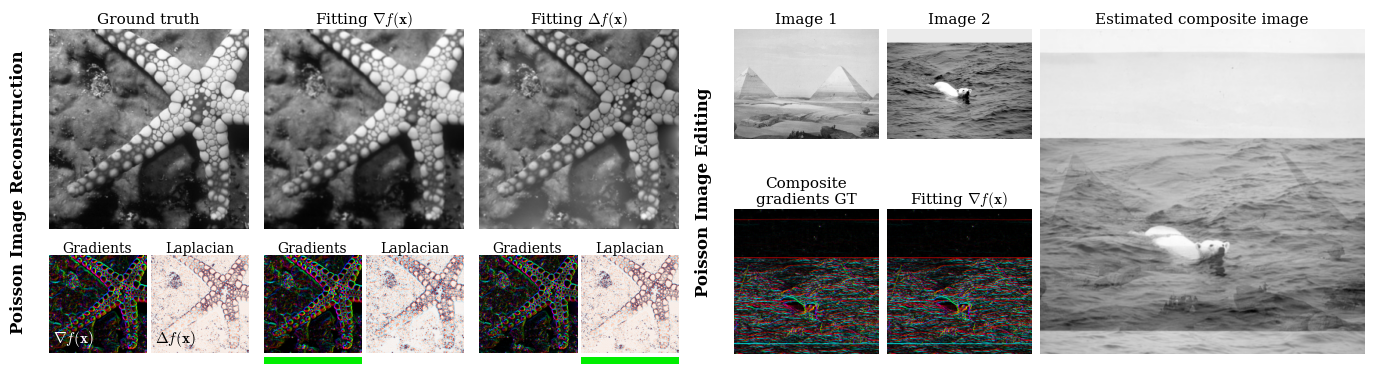

已保存到: /content/drive/MyDrive/siren_reproduction


In [ ]:
# ============================================================
# Fig.3 reproduction: use the images the official summary functions wrote to TensorBoard
# ============================================================
import io, os, shutil
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorboard.backend.event_processing import event_accumulator

LOG = "/content/drive/MyDrive/siren_reproduction/logs"
SAVE_DIR = "/content/drive/MyDrive/siren_reproduction"
EXP_GRAD, EXP_LAPL = "poisson_grad", "poisson_lapl"
EXP_COMP_CANDIDATES = ["poisson_comp_v2", "poisson_comp"]   # prefer the cut-out version

# ---------------- Read the official images from TensorBoard ----------------
def load_ea(exp):
    d = f"{LOG}/{exp}/summaries"
    if not os.path.isdir(d):
        return None
    ea = event_accumulator.EventAccumulator(d, size_guidance={'images': 0})
    ea.Reload()
    return ea

def last_img(ea, tag, exp):
    tags = ea.Tags()['images']
    assert tag in tags, f"[{exp}] has no tag '{tag}'; available tags: {tags}"
    ev = ea.Images(tag)[-1]
    return np.array(Image.open(io.BytesIO(ev.encoded_image_string)).convert("RGB")), ev.step

ea_grad = load_ea(EXP_GRAD)
ea_lapl = load_ea(EXP_LAPL)
assert ea_grad and ea_lapl, "Logs for poisson_grad / poisson_lapl not found"

EXP_COMP, ea_comp = next(((e, load_ea(e)) for e in EXP_COMP_CANDIDATES if load_ea(e)), (None, None))
assert ea_comp, f"No logs found for any of {EXP_COMP_CANDIDATES}"
if EXP_COMP != EXP_COMP_CANDIDATES[0]:
    print(f"⚠ {EXP_COMP_CANDIDATES[0]} not found; falling back to {EXP_COMP}")

def get(ea, tag, exp):
    img, step = last_img(ea, tag, exp)
    print(f"  {exp:16s} {tag:24s} step={step:6d} size={img.shape[1]}x{img.shape[0]}")
    return img

print("Reading official images:")
gt_img    = get(ea_grad, "train_gt_img",   EXP_GRAD)
gt_grad   = get(ea_grad, "train_gt_grad",  EXP_GRAD)
gt_lapl   = get(ea_lapl, "train_gt_lapl",  EXP_LAPL)

pg_img    = get(ea_grad, "train_pred_img",  EXP_GRAD)
pg_grad   = get(ea_grad, "train_pred_grad", EXP_GRAD)
pg_lapl   = get(ea_grad, "train_pred_lapl", EXP_GRAD)

pl_img    = get(ea_lapl, "train_pred_img",  EXP_LAPL)
pl_grad   = get(ea_lapl, "train_pred_grad", EXP_LAPL)
pl_lapl   = get(ea_lapl, "train_pred_lapl", EXP_LAPL)

c_img1    = get(ea_comp, "train_gt_img1",        EXP_COMP)
c_img2    = get(ea_comp, "train_gt_img2",        EXP_COMP)
c_gt_grad = get(ea_comp, "train_gt_gradcomp",    EXP_COMP)
c_pr_grad = get(ea_comp, "train_pred_gradcomp",  EXP_COMP)
c_pr_img  = get(ea_comp, "train_pred_comp_img",  EXP_COMP)

recon_cols = [
    ("Ground truth",                    gt_img, gt_grad, gt_lapl),
    (r"Fitting $\nabla f(\mathbf{x})$", pg_img, pg_grad, pg_lapl),
    (r"Fitting $\Delta f(\mathbf{x})$", pl_img, pl_grad, pl_lapl),
]

# ---------------- Assemble the figure in the paper's Fig.3 layout ----------------
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm"})
W, H = 13.6, 3.8
fig = plt.figure(figsize=(W, H))

def ax_at(x, y, w, h):
    a = fig.add_axes([x / W, y / H, w / W, h / H])
    a.set_xticks([]); a.set_yticks([])
    for s in a.spines.values():
        s.set_visible(False)
    return a

TS = 11
Y_BOT, Y_TOP = 0.15, 3.40

# ===== Left: Poisson Image Reconstruction =====
fig.text(0.15 / W, (Y_BOT + Y_TOP) / 2 / H, "Poisson Image Reconstruction", rotation=90,
         va="center", ha="center", fontsize=12, fontweight="bold")

x0, colw, gap = 0.45, 2.0, 0.15
for c, (title, im, g, l) in enumerate(recon_cols):
    xc = x0 + c * (colw + gap)
    a = ax_at(xc, Y_TOP - 2.0, colw, 2.0)
    a.imshow(im)
    a.set_title(title, fontsize=TS, pad=4)

    ag = ax_at(xc, Y_BOT, colw / 2 - 0.02, 1.0)
    ag.imshow(g)
    ag.set_title("Gradients", fontsize=TS - 1, pad=2)

    al = ax_at(xc + colw / 2 + 0.02, Y_BOT, colw / 2 - 0.02, 1.0)
    al.imshow(l)
    al.set_title("Laplacian", fontsize=TS - 1, pad=2)

    if c == 0:
        ag.text(0.05, 0.05, r"$\nabla f(\mathbf{x})$", transform=ag.transAxes,
                color="white", fontsize=TS, va="bottom")
        al.text(0.05, 0.05, r"$\Delta f(\mathbf{x})$", transform=al.transAxes,
                color="black", fontsize=TS, va="bottom")
    if c == 1:
        ax_at(xc, Y_BOT - 0.10, colw / 2 - 0.02, 0.07).set_facecolor("#00ee00")
    if c == 2:
        ax_at(xc + colw / 2 + 0.02, Y_BOT - 0.10, colw / 2 - 0.02, 0.07).set_facecolor("#00ee00")

# ===== Right: Poisson Image Editing =====
xr_label = x0 + 3 * colw + 2 * gap + 0.25
fig.text(xr_label / W, (Y_BOT + Y_TOP) / 2 / H, "Poisson Image Editing", rotation=90,
         va="center", ha="center", fontsize=12, fontweight="bold")

xr, sw, sg = xr_label + 0.3, 1.45, 0.08
top_h, bot_h = 1.10, 1.45

S = c_img1.shape[0]
crop_h = int(round(S * top_h / sw))
c1 = (S - crop_h) // 2
im1_crop = c_img1[c1:c1 + crop_h]       # Image 1: crop the middle
im2_crop = c_img2[S - crop_h:]          # Image 2: keep the lower part where the bear is

a = ax_at(xr, Y_TOP - top_h, sw, top_h);           a.imshow(im1_crop, aspect="auto"); a.set_title("Image 1", fontsize=TS, pad=4)
a = ax_at(xr + sw + sg, Y_TOP - top_h, sw, top_h); a.imshow(im2_crop, aspect="auto"); a.set_title("Image 2", fontsize=TS, pad=4)
a = ax_at(xr, Y_BOT, sw, bot_h);                   a.imshow(c_gt_grad, aspect="auto"); a.set_title("Composite\ngradients GT", fontsize=TS, pad=4)
a = ax_at(xr + sw + sg, Y_BOT, sw, bot_h);         a.imshow(c_pr_grad, aspect="auto"); a.set_title(r"Fitting $\nabla f(\mathbf{x})$", fontsize=TS, pad=4)

big = Y_TOP - Y_BOT
a = ax_at(xr + 2 * sw + 2 * sg, Y_BOT, big, big)
a.imshow(c_pr_img)
a.set_title("Estimated composite image", fontsize=TS, pad=4)

plt.savefig("fig3_reproduction.png", dpi=250, bbox_inches="tight")
plt.savefig("fig3_reproduction.pdf", bbox_inches="tight")
plt.show()

for f in ["fig3_reproduction.png", "fig3_reproduction.pdf"]:
    shutil.copy(f, f"{SAVE_DIR}/{f}")
print("Saved to:", SAVE_DIR)

**Reproduce Fig. 3.** Reads the images that the official summary functions logged to TensorBoard for the three Poisson runs (ground truth, reconstructions, gradients, Laplacians, the two input images, the composite gradients and the composite result), without re-rendering or recoloring anything. It then places them in the paper's Fig. 3 layout, including the green bars marking the supervised quantity, and saves `fig3_reproduction.png` / `.pdf` to Drive. If `poisson_comp_v2` is missing it falls back to `poisson_comp`.

In [ ]:
# ================= Download official data: Thai Statue and living-room point clouds =================
# Source: the shared data folder linked by the SIREN authors in the README
!pip install -q -U gdown
import gdown, os

FOLDER_URL = "https://drive.google.com/drive/folders/1_iq__37-hw7FJOEUK1tX7mdp8SKB368K"
TARGETS = {                                   # file name in the shared folder -> local path
    "thai_statue.xyz":   "/content/thai_statue.xyz",
    "interior_room.xyz": "/content/interior_room.xyz",
}

# List the folder contents only, without downloading
files = gdown.download_folder(FOLDER_URL, skip_download=True, quiet=True)
print(".xyz files in the shared folder:")
for f in files:
    if f.path.endswith(".xyz"):
        print(f"  {f.path}   id={f.id}")

# Download only the two files we need
for f in files:
    name = os.path.basename(f.path)
    if name in TARGETS:
        out = TARGETS[name]
        if os.path.exists(out) and os.path.getsize(out) > 0:
            print(f"Already exists, skipping: {out}")
        else:
            gdown.download(id=f.id, output=out, quiet=False)

for name, out in TARGETS.items():
    assert os.path.exists(out) and os.path.getsize(out) > 0, \
        f"{name} was not downloaded: check the file list printed above and change the file names in TARGETS to the actual names"
    print(f"✅ {out}  {os.path.getsize(out) / 1e6:.0f} MB")

**Download the SDF point clouds.** Lists the authors' shared Google Drive folder and downloads only the two point clouds needed for Fig. 4 (`thai_statue.xyz` and `interior_room.xyz`), skipping files that already exist and checking that both are present.

In [ ]:
import numpy as np
import pandas as pd

LOG = "/content/drive/MyDrive/siren_reproduction/logs"
BATCH = 250000
DATA = {
    "thai": "/content/thai_statue.xyz",
    "room": "/content/interior_room.xyz",
}

# ================= Data check =================
for name, path in DATA.items():
    print(f"\n=== Checking {name}: {path} ===")
    df = pd.read_csv(path, sep=r"\s+", header=None)   # much faster than genfromtxt; used for checking only
    arr = df.to_numpy(dtype=np.float64)
    n, c = arr.shape
    print(f"  Points: {n:,}    Columns: {c}")
    assert c == 6, f"{name}: expected 6 columns (xyz + normals), got {c}"
    assert np.isfinite(arr).all(), f"{name}: contains NaN or inf"
    assert n >= BATCH, f"{name}: point count {n} is smaller than batch_size {BATCH}"

    xyz, nrm = arr[:, :3], arr[:, 3:]
    nlen = np.linalg.norm(nrm, axis=1)
    n_zero = int((nlen < 1e-8).sum())
    print(f"  Coordinate range: min={xyz.min(0).round(3)}  max={xyz.max(0).round(3)}")
    print(f"  Normal length: min={nlen.min():.3f}  mean={nlen.mean():.3f}  max={nlen.max():.3f}")
    print(f"  Zero normals: {n_zero} ({n_zero / n:.4%})")
    print(f"  Steps per epoch: {n // BATCH}; total over 10000 epochs: {n // BATCH * 10000:,} steps")
    # Zero normals make cosine_similarity degenerate; a few are fine, too many must be handled
    assert n_zero / n < 0.01, f"{name}: more than 1% zero normals; fix them before training"
    del df, arr

print("\n✅ Both datasets passed the check; starting training\n")

# ================= Train the 4 experiments in order =================
!python experiment_scripts/train_sdf.py --model_type=sine --point_cloud_path=/content/thai_statue.xyz \
    --batch_size=250000 --epochs_til_ckpt=100 --experiment_name=sdf_thai_sine --logging_root={LOG}

!python experiment_scripts/train_sdf.py --model_type=relu --point_cloud_path=/content/thai_statue.xyz \
    --batch_size=250000 --epochs_til_ckpt=100 --experiment_name=sdf_thai_relu --logging_root={LOG}

!python experiment_scripts/train_sdf.py --model_type=sine --point_cloud_path=/content/interior_room.xyz \
    --batch_size=250000 --epochs_til_ckpt=100 --experiment_name=sdf_room_sine --logging_root={LOG}

!python experiment_scripts/train_sdf.py --model_type=relu --point_cloud_path=/content/interior_room.xyz \
    --batch_size=250000 --epochs_til_ckpt=100 --experiment_name=sdf_room_relu --logging_root={LOG}

**Check the point clouds, then train the SDF models.** Loads each point cloud and checks that it has 6 columns (xyz + normals), contains no NaN/inf, has at least one batch of points, and has under 1% zero-length normals; it also prints coordinate ranges, normal lengths and the number of steps per epoch. If all checks pass, it trains four SDF models with the official `train_sdf.py` and the README settings (`batch_size=250000`): Thai statue with SIREN and ReLU, then the room with SIREN and ReLU. `epochs_til_ckpt=100` only reduces how often checkpoints are written.

In [13]:
import os, glob, subprocess, sys

LOG = "/content/drive/MyDrive/siren_reproduction/logs"
%cd /content/siren

# ========== 1. Status of the four models ==========
# Room · SIREN was resumed from a checkpoint; its final weights are in sdf_room_sine_resume
RUNS = {
    "thai_sine": ("sdf_thai_sine",        "sine"),
    "thai_relu": ("sdf_thai_relu",        "relu"),
    "room_sine": ("sdf_room_sine_resume", "sine"),
    "room_relu": ("sdf_room_relu",        "relu"),
}
ready = {}
for name, (exp, mtype) in RUNS.items():
    final = f"{LOG}/{exp}/checkpoints/model_final.pth"
    ok = os.path.exists(final)
    print(f"{name:10s} {'✅ Done' if ok else '❌ No model_final.pth yet'}   {final}")
    if ok:
        ready[name] = (final, mtype)

# ========== 2. Make the mesh-extraction code compatible with newer scikit-image ==========
# marching_cubes_lewiner used by the old code was removed in scikit-image 0.19; replace it with the equivalent marching_cubes
src = open("sdf_meshing.py").read()
if "marching_cubes_lewiner" in src:
    open("sdf_meshing.py", "w").write(src.replace("marching_cubes_lewiner", "marching_cubes"))
    print("\nReplaced marching_cubes_lewiner with marching_cubes")
!grep -n "marching_cubes\|N=\|max_batch" sdf_meshing.py | head

/content/siren
thai_sine  ✅ 已完成   /content/drive/MyDrive/siren_reproduction/logs/sdf_thai_sine/checkpoints/model_final.pth
thai_relu  ✅ 已完成   /content/drive/MyDrive/siren_reproduction/logs/sdf_thai_relu/checkpoints/model_final.pth
room_sine  ✅ 已完成   /content/drive/MyDrive/siren_reproduction/logs/sdf_room_sine_resume/checkpoints/model_final.pth
room_relu  ✅ 已完成   /content/drive/MyDrive/siren_reproduction/logs/sdf_room_relu/checkpoints/model_final.pth

已把 marching_cubes_lewiner 换成 marching_cubes
14:    decoder, filename, N=256, max_batch=64 ** 3, offset=None, scale=None
48:        sample_subset = samples[head : min(head + max_batch, num_samples), 0:3].cuda()
50:        samples[head : min(head + max_batch, num_samples), 3] = (
56:        head += max_batch
99:        verts, faces, normals, values = skimage.measure.marching_cubes(
106:    # note x and y are flipped in the output of marching_cubes


**Check the trained models and prepare mesh extraction.** Reports which of the four SDF models have a `model_final.pth` (the room SIREN model comes from the resumed run `sdf_room_sine_resume`). It also replaces `marching_cubes_lewiner`, which was removed in scikit-image 0.19, with `marching_cubes` in `sdf_meshing.py`; in current scikit-image this function uses the Lewiner method by default, so the extracted surface is the same.

In [ ]:
# ========== 3. Extract meshes (official default resolution 1600³) ==========
for name, (ckpt, mtype) in ready.items():
    out_exp = f"mesh_{name}"
    if os.path.exists(f"{LOG}/{out_exp}/test.ply"):
        print("Already exists, skipping:", out_exp); continue
    print(f"\n===== Extracting {name} =====", flush=True)
    !python experiment_scripts/test_sdf.py --checkpoint_path={ckpt} --model_type={mtype} \
        --experiment_name={out_exp} --logging_root={LOG}
    !ls -lh {LOG}/{out_exp}/

**Extract the meshes.** For every finished model, runs the official `test_sdf.py`, which evaluates the SDF on a 1600³ grid (the official default) and extracts the zero level set with marching cubes into `test.ply`. Models whose mesh already exists are skipped.

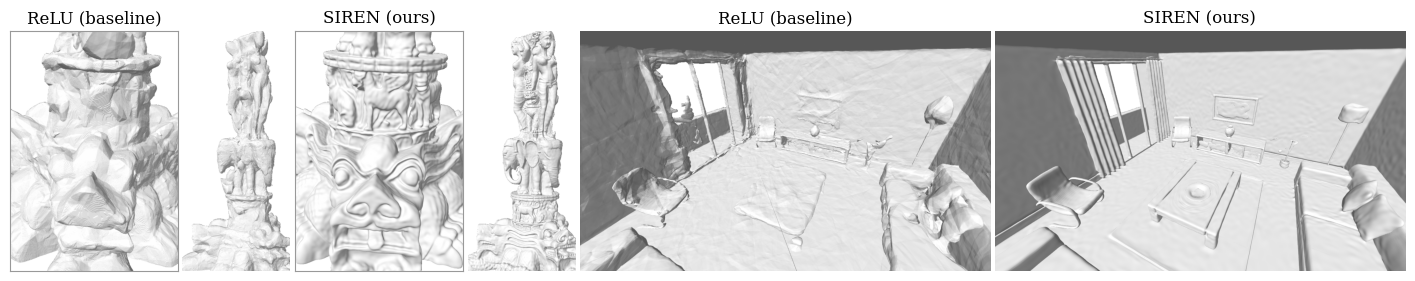

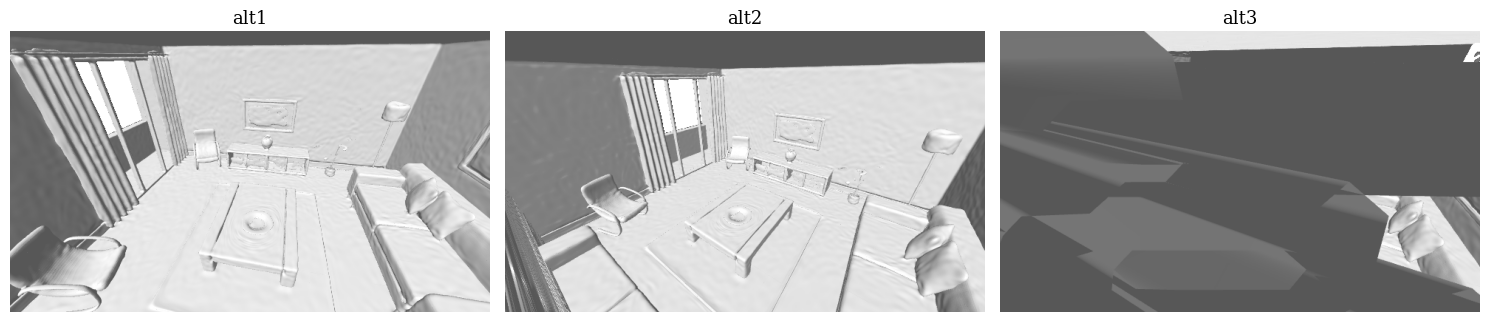

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
import warnings; warnings.filterwarnings("ignore", message="Glyph")
import numpy as np, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from google.colab import files

# ---------- Rendering with side lighting: key light from the upper-left front, matching the shading direction in the paper ----------
def render2(path, eye, target, up, size=(900, 900), yfov=np.pi / 5):
    mat = pyrender.MetallicRoughnessMaterial(baseColorFactor=[0.78, 0.78, 0.78, 1.0],
                                             metallicFactor=0.0, roughnessFactor=0.8)
    scene = pyrender.Scene(bg_color=[1, 1, 1, 1], ambient_light=[0.12] * 3)
    scene.add(pyrender.Mesh.from_trimesh(load(path), material=mat, smooth=True))
    cam_pose = look_at(eye, target, up)
    scene.add(pyrender.PerspectiveCamera(yfov=yfov, znear=0.005), pose=cam_pose)
    fwd = target - eye; dist = np.linalg.norm(fwd); fwd /= dist
    right = np.cross(fwd, up); right /= np.linalg.norm(right)
    key_pos = eye + (up * 0.9 - right * 0.7) * dist          # upper left
    scene.add(pyrender.DirectionalLight(intensity=3.2), pose=look_at(key_pos, target, up))
    scene.add(pyrender.DirectionalLight(intensity=1.0), pose=cam_pose)   # weak fill light
    r = pyrender.OffscreenRenderer(*size)
    img, depth = r.render(scene, flags=pyrender.RenderFlags.SKIP_CULL_FACES); r.delete()
    img = img.copy(); img[depth == 0] = 255
    return img

# ---------- Statue cameras ----------
p = MESH["thai_sine"]
b = load(p).bounds; c, ext = b.mean(0), b[1] - b[0]
srt = np.argsort(ext)[::-1]
UP = np.eye(3)[srt[0]]; H = ext[srt[0]]
A = np.eye(3)[srt[2]]                                   # only side A has the beast face

tgt = c + UP * (-0.34) * H
DIST = 1.2                                                     # 1.0 = the current distance; larger = farther
THAI_CLOSE = (tgt + (A * 0.50 + UP * 0.18) * DIST * H, tgt, UP)
side = next(V for V in [np.eye(3)[srt[1]], -np.eye(3)[srt[1]]]
            if np.dot(np.cross(-V, UP), A) < 0)         # side A falls on the left of the frame (matches the camera icon in the paper)
THAI_FULL = (c + side * 1.6 * H, c, UP)                 # move closer so the statue fills the height

# ---------- Room camera: near the -z side, looking toward -x, tilted slightly toward +z so the curtain wall on the left is in view ----------
q = MESH["room_sine"]
b = load(q).bounds; rc, rext = b.mean(0), b[1] - b[0]
Y = np.array([0.0, 1.0, 0.0])
ROOM_OPTS = {
    "main": ([0.30, 0.36, -0.20], [-0.30, -0.35, 0.05]),
    "alt1": ([0.30, 0.36, -0.10], [-0.30, -0.35, 0.00]),
    "alt2": ([0.30, 0.36, -0.28], [-0.30, -0.35, 0.10]),
    "alt3": ([0.34, 0.42, -0.20], [-0.30, -0.35, 0.05]),
}
cam = lambda k: (rc + np.array(ROOM_OPTS[k][0]) * rext, rc + np.array(ROOM_OPTS[k][1]) * rext, Y)

# ---------- Render the final figure ----------
R = {}
for m in ["relu", "sine"]:
    R[f"thai_{m}_close"] = render2(MESH[f"thai_{m}"], *THAI_CLOSE, size=(700, 1000))
    R[f"thai_{m}_full"]  = render2(MESH[f"thai_{m}"], *THAI_FULL,  size=(450, 1000))
    R[f"room_{m}"]       = render2(MESH[f"room_{m}"], *cam("main"), size=(1300, 760), yfov=np.pi / 2.4)

plt.rcParams.update({"font.family": "serif"})
fig = plt.figure(figsize=(18, 3.9))
gs = GridSpec(1, 6, width_ratios=[0.7, 0.45, 0.7, 0.45, 1.71, 1.71], wspace=0.02)
panels = [("thai_relu_close", "ReLU (baseline)", True),  ("thai_relu_full", "", False),
          ("thai_sine_close", "SIREN (ours)", True),     ("thai_sine_full", "", False),
          ("room_relu", "ReLU (baseline)", False),       ("room_sine", "SIREN (ours)", False)]
for i, (k, title, boxed) in enumerate(panels):
    ax = fig.add_subplot(gs[i]); ax.imshow(R[k]); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(boxed); s.set_edgecolor("#999999")
    if title: ax.set_title(title, fontsize=12)
SAVE = "/content/drive/MyDrive/siren_reproduction"
plt.savefig(f"{SAVE}/fig4_reproduction.png", dpi=250, bbox_inches="tight")
plt.savefig(f"{SAVE}/fig4_reproduction.pdf", bbox_inches="tight")
plt.show()

# ---------- 3 alternative room views (SIREN only) ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, k in zip(axes, ["alt1", "alt2", "alt3"]):
    ax.imshow(render2(MESH["room_sine"], *cam(k), size=(650, 380), yfov=np.pi / 2.4))
    ax.set_title(k, fontsize=13); ax.axis("off")
plt.tight_layout(); plt.savefig("/content/fig4_room_alts.png", dpi=80, bbox_inches="tight"); plt.show()
files.download("/content/fig4_room_alts.png")

**Reproduce Fig. 4.** Renders the extracted meshes with pyrender: gray material, white background, a key light from the upper left and a weak fill light. The statue gets a close-up camera on the beast face (side A, viewed slightly from above) and a full-body camera from the side; the room gets a camera inside the room. ReLU and SIREN use exactly the same cameras. The results are arranged in the paper's Fig. 4 layout and saved as `fig4_reproduction.png` / `.pdf` to Drive. It also renders three alternative room viewpoints (SIREN only) and downloads them for comparison. This cell uses `pyrender`, `load`, `look_at` and `MESH` from the earlier rendering-setup cell.